In [ ]:
#connecting google colab to google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# loading dataset from google drive
import pandas as pd
file_path = '/content/drive/MyDrive/Solar Wind Updated.xlsx'
df = pd.read_excel(file_path)

In [ ]:

df.head()

,period,timedelta,bx_gse,by_gse,bz_gse,theta_gse,phi_gse,bx_gsm,by_gsm,bz_gsm,theta_gsm,phi_gsm,bt,density,speed,temperature,source
0,train_a,0 days 00:00:00,-5.55,3.00,1.25,11.09,153.37,-5.55,3.00,1.25,11.09,153.37,6.80,1.53,383.92,110237.0,ac
1,train_a,0 days 00:01:00,-5.58,3.16,1.17,10.10,151.91,-5.58,3.16,1.17,10.10,151.91,6.83,1.69,381.79,123825.0,ac
2,train_a,0 days 00:02:00,-5.15,3.66,0.85,7.87,146.04,-5.15,3.66,0.85,7.87,146.04,6.77,1.97,389.11,82548.0,ac
3,train_a,0 days 00:03:00,-5.20,3.68,0.68,6.17,146.17,-5.20,3.68,0.68,6.17,146.17,6.74,1.97,389.11,82548.0,ac
4,train_a,0 days 00:04:00,-5.12,3.68,0.49,4.62,145.72,-5.12,3.68,0.49,4.62,145.72,6.65,1.77,384.26,94269.0,ac


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 527040 entries, 0 to 527039
Data columns (total 17 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   period       527040 non-null  object 
 1   timedelta    527040 non-null  object 
 2   bx_gse       444948 non-null  float64
 3   by_gse       444948 non-null  float64
 4   bz_gse       444948 non-null  float64
 5   theta_gse    444948 non-null  float64
 6   phi_gse      444948 non-null  float64
 7   bx_gsm       444948 non-null  float64
 8   by_gsm       444948 non-null  float64
 9   bz_gsm       444948 non-null  float64
 10  theta_gsm    444948 non-null  float64
 11  phi_gsm      444948 non-null  float64
 12  bt           444948 non-null  float64
 13  density      354773 non-null  float64
 14  speed        354778 non-null  float64
 15  temperature  351668 non-null  float64
 16  source       445503 non-null  object 
dtypes: float64(14), object(3)
memory usage: 68.4+ MB


In [ ]:
df.describe()

,bx_gse,by_gse,bz_gse,theta_gse,phi_gse,bx_gsm,by_gsm,bz_gsm,theta_gsm,phi_gsm,bt,density,speed,temperature
count,444948.000000,444948.000000,444948.000000,444948.000000,444948.000000,444948.000000,444948.000000,444948.000000,444948.000000,444948.000000,444948.000000,354773.000000,354778.000000,3.516680e+05
mean,-1.631041,0.473027,-0.206760,-1.464696,185.692918,-1.631193,0.382731,-0.251981,-1.941607,186.003248,7.102786,5.261442,419.473613,9.709464e+04
std,4.369921,4.652605,4.156708,33.073642,87.883857,4.370411,4.608383,4.211791,33.883664,87.958901,3.449864,4.544309,79.292867,8.343878e+04
min,-40.180000,-36.750000,-26.840000,-89.580000,0.000000,-40.170000,-37.570000,-33.910000,-89.760000,0.000000,0.070000,0.000000,237.840000,1.000000e+04
25%,-4.970000,-2.620000,-2.510000,-24.170000,128.030000,-4.970000,-2.580000,-2.620000,-25.540000,128.800000,5.000000,2.500000,366.660000,4.154800e+04
50%,-1.890000,0.650000,-0.120000,-1.160000,169.130000,-1.890000,0.550000,-0.230000,-2.260000,170.500000,6.410000,4.090000,405.760000,7.538400e+04
75%,1.800000,3.450000,2.150000,20.940000,263.780000,1.800000,3.290000,2.200000,21.490000,263.140000,8.270000,6.500000,456.530000,1.241162e+05
max,41.130000,36.700000,74.030000,89.700000,360.000000,41.130000,36.610000,72.450000,89.590000,360.000000,80.530000,152.030000,898.870000,1.595840e+06


In [ ]:
#selecting only usefull features
features = ['timedelta', 'by_gsm','bz_gsm','bt','density','speed','temperature']
df_shrink = df[features].copy()

In [ ]:
import numpy as np

placeholders = [999, 999.9, 9999, 99999, -9999.9]
df_shrink.replace(placeholders, np.nan, inplace=True)
df_shrink['timedelta'] = pd.to_timedelta(df_shrink['timedelta'])
df_shrink.set_index('timedelta', inplace=True)

In [ ]:
features = ['by_gsm','bz_gsm','bt','density','speed','temperature']
df_hourly = df_shrink[features].resample('1h').mean()
df_counts = df_shrink[features].resample('1h').count()
threshold = 40
mask = (df_counts < threshold).any(axis=1)
df_hourly[mask] = np.nan
df_hourly = df_hourly.interpolate(method='linear', limit=2)
df_hourly = df_hourly.ffill().bfill()
for col in ['bz_gsm', 'by_gsm', 'bt', 'density', 'speed', 'temperature']:
    df_hourly[f'{col}_1h'] = df_hourly[col].shift(1)
    df_hourly[f'{col}_3h'] = df_hourly[col].shift(3)
    df_hourly[f'{col}_6h'] = df_hourly[col].shift(6)
df_final = df_hourly.dropna()

print(f"Final rows     : {len(df_final)}")
print(f"Total features : {len(df_final.columns)}")
print(df_final.head())

Final rows     : 8778
Total features : 24
                   by_gsm    bz_gsm        bt   density       speed  \
timedelta                                                             
0 days 06:00:00 -4.238545  0.857091  6.635455  5.977500  398.400962   
0 days 07:00:00 -5.021800  0.209200  6.193200  5.799792  413.394792   
0 days 08:00:00 -4.386833  0.636667  5.885000  7.762105  406.048421   
0 days 09:00:00 -3.406333  1.138500  5.728667  8.750172  396.374828   
0 days 10:00:00 -2.613167  2.127333  6.148500  8.538947  390.847719   

                  temperature  bz_gsm_1h  bz_gsm_3h  bz_gsm_6h  by_gsm_1h  \
timedelta                                                                   
0 days 06:00:00  52607.692308   0.738333   1.770333   0.844667  -3.934167   
0 days 07:00:00  47018.333333   0.857091   1.254333   1.265167  -4.238545   
0 days 08:00:00  38852.473684   0.209200   0.738333   1.517750  -5.021800   
0 days 09:00:00  32037.689655   0.636667   0.857091   1.770333  -4.386833  

In [ ]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
TimedeltaIndex: 8778 entries, 0 days 06:00:00 to 365 days 23:00:00
Freq: h
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   by_gsm          8778 non-null   float64
 1   bz_gsm          8778 non-null   float64
 2   bt              8778 non-null   float64
 3   density         8778 non-null   float64
 4   speed           8778 non-null   float64
 5   temperature     8778 non-null   float64
 6   bz_gsm_1h       8778 non-null   float64
 7   bz_gsm_3h       8778 non-null   float64
 8   bz_gsm_6h       8778 non-null   float64
 9   by_gsm_1h       8778 non-null   float64
 10  by_gsm_3h       8778 non-null   float64
 11  by_gsm_6h       8778 non-null   float64
 12  bt_1h           8778 non-null   float64
 13  bt_3h           8778 non-null   float64
 14  bt_6h           8778 non-null   float64
 15  density_1h      8778 non-null   float64
 16  density_3h      8778 non-null   float64

In [ ]:
df_final.describe()

,by_gsm,bz_gsm,bt,density,speed,temperature,bz_gsm_1h,bz_gsm_3h,bz_gsm_6h,by_gsm_1h,...,bt_6h,density_1h,density_3h,density_6h,speed_1h,speed_3h,speed_6h,temperature_1h,temperature_3h,temperature_6h
count,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,...,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000,8778.000000
mean,0.402599,-0.149871,7.057351,5.088107,417.348744,95714.324588,-0.149802,-0.150241,-0.149769,0.401484,...,7.058456,5.088504,5.088770,5.088380,417.341538,417.319791,417.281973,95717.773241,95721.553108,95718.811869
std,4.179944,3.754275,3.238666,4.206236,77.202022,73463.479851,3.754286,3.753966,3.753978,4.179795,...,3.238370,4.206168,4.206056,4.206357,77.201033,77.203974,77.213632,73461.297663,73459.735072,73460.645701
min,-19.812833,-17.768167,0.838667,0.123750,274.011552,11302.927273,-17.768167,-17.768167,-17.768167,-19.812833,...,0.838667,0.123750,0.123750,0.123750,274.011552,274.011552,274.011552,11302.927273,11302.927273,11302.927273
25%,-2.267800,-2.111618,5.053208,2.504918,366.470241,44551.369166,-2.111618,-2.111618,-2.111618,-2.268325,...,5.054000,2.504918,2.506101,2.505097,366.470241,366.439188,366.348462,44552.358763,44552.358763,44552.358763
50%,0.560667,-0.068990,6.337596,4.070081,403.521466,78930.940390,-0.068990,-0.068990,-0.068407,0.559222,...,6.338537,4.071112,4.072446,4.072446,403.494248,403.478017,403.422649,78930.940390,78930.940390,78930.940390
75%,2.975882,1.873497,8.151625,6.166667,450.487291,120323.638698,1.873497,1.873497,1.873497,2.974146,...,8.151625,6.166667,6.166667,6.166667,450.345767,450.265795,450.228772,120323.638698,120323.638698,120323.638698
max,31.109667,23.910833,34.600667,58.908600,846.166122,962957.020408,23.910833,23.910833,23.910833,31.109667,...,34.600667,58.908600,58.908600,58.908600,846.166122,846.166122,846.166122,962957.020408,962957.020408,962957.020408


In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
df_sandbox = df_final.copy()

# Min-Max Scaling (Squashes everything between 0 and 1)
mm_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(
    mm_scaler.fit_transform(df_sandbox),
    columns=df_sandbox.columns,
    index=df_sandbox.index
)

# Standardization (Centers data around 0 with a 'Standard Deviation' of 1)

std_scaler = StandardScaler()
df_standard = pd.DataFrame(
    std_scaler.fit_transform(df_sandbox),
    columns=df_sandbox.columns,
    index=df_sandbox.index
)

print("--- ORIGINAL DATA (Speed Example) ---")
print(df_final['speed'].head(3))

print("\n--- MIN-MAX SCALED (0 to 1) ---")
print(df_minmax['speed'].head(3))

print("\n--- STANDARD SCALED (Mean=0, Std=1) ---")
print(df_standard['speed'].head(3))

--- ORIGINAL DATA (Speed Example) ---
timedelta
0 days 06:00:00    398.400962
0 days 07:00:00    413.394792
0 days 08:00:00    406.048421
Freq: h, Name: speed, dtype: float64

--- MIN-MAX SCALED (0 to 1) ---
timedelta
0 days 06:00:00    0.217405
0 days 07:00:00    0.243611
0 days 08:00:00    0.230771
Freq: h, Name: speed, dtype: float64

--- STANDARD SCALED (Mean=0, Std=1) ---
timedelta
0 days 06:00:00   -0.245445
0 days 07:00:00   -0.051219
0 days 08:00:00   -0.146382
Freq: h, Name: speed, dtype: float64


In [ ]:
# 1. Load the labels
labels_path = '/content/drive/MyDrive/Solar wind Labels.csv'
df_labels = pd.read_csv(labels_path)


df_labels['timedelta'] = pd.to_timedelta(df_labels['timedelta'])
df_labels.set_index('timedelta', inplace=True)

df_labels= df_labels.drop(columns=['period'])


df_labels_hourly = df_labels.resample('1h').first()
df_labels.head()

,dst
timedelta,
0 days 00:00:00,-7
0 days 01:00:00,-10
0 days 02:00:00,-10
0 days 03:00:00,-6
0 days 04:00:00,-2


In [ ]:
# Merge features and labels based on the Timedelta Index
df_master = df_final.join(df_labels_hourly, how='inner')

print(f"Features rows: {len(df_final)}")
print(f"Labels rows: {len(df_labels_hourly)}")
print(f"Final combined rows for ML: {len(df_master)}")

# Check if there are any missing values after the merge
print(df_master.isnull().sum())

Features rows: 8778
Labels rows: 52584
Final combined rows for ML: 8778
by_gsm            0
bz_gsm            0
bt                0
density           0
speed             0
temperature       0
bz_gsm_1h         0
bz_gsm_3h         0
bz_gsm_6h         0
by_gsm_1h         0
by_gsm_3h         0
by_gsm_6h         0
bt_1h             0
bt_3h             0
bt_6h             0
density_1h        0
density_3h        0
density_6h        0
speed_1h          0
speed_3h          0
speed_6h          0
temperature_1h    0
temperature_3h    0
temperature_6h    0
dst               0
dtype: int64


In [ ]:
df_master['label'] = (df_master['dst'] <= -50).astype(int)
print("Target counts:")
print(df_master['label'].value_counts())
X = df_master.drop(columns=['label', 'dst'])
y = df_master['label']

Target counts:
label
0    8150
1     628
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (7022, 24)
X_test shape: (1756, 24)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)
print(f"New Training Size: {len(y_train_bal)} (Balanced 50/50)")
rf_bal = RandomForestClassifier(n_estimators=100, random_state=42)
rf_bal.fit(X_train_bal, y_train_bal)
rf_bal_preds = rf_bal.predict(X_test)
xgb_bal = XGBClassifier(random_state=42)
xgb_bal.fit(X_train_bal, y_train_bal)
xgb_bal_preds = xgb_bal.predict(X_test)

New Training Size: 13040 (Balanced 50/50)


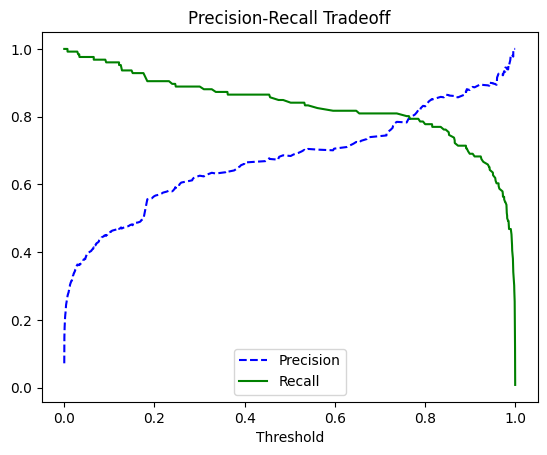

In [ ]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

rf_proba  = rf_bal.predict_proba(X_test)[:, 1]
xgb_proba = xgb_bal.predict_proba(X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, xgb_proba)
plt.plot(thresholds, precision[:-1], 'b--', label='Precision')
plt.plot(thresholds, recall[:-1], 'g-', label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision-Recall Tradeoff')
plt.show()

In [ ]:
import numpy as np

rf_proba  = rf_bal.predict_proba(X_test)[:, 1]
xgb_proba = xgb_bal.predict_proba(X_test)[:, 1]
rf_tuned  = (rf_proba  >= 0.7).astype(int)
xgb_tuned = (xgb_proba >= 0.7).astype(int)

print("=== RF SMOTE + THRESHOLD 0.7 ===")
print(classification_report(y_test, rf_tuned, target_names=['Quiet','Storm']))
# write threshold instead of 0.
print("=== XGB SMOTE + THRESHOLD 0.7 ===")
print(classification_report(y_test, xgb_tuned, target_names=['Quiet','Storm']))

=== RF SMOTE + THRESHOLD 0.7 ===
              precision    recall  f1-score   support

       Quiet       0.97      0.99      0.98      1630
       Storm       0.83      0.67      0.74       126

    accuracy                           0.97      1756
   macro avg       0.90      0.83      0.86      1756
weighted avg       0.96      0.97      0.96      1756

=== XGB SMOTE + THRESHOLD 0.7 ===
              precision    recall  f1-score   support

       Quiet       0.99      0.98      0.98      1630
       Storm       0.74      0.81      0.78       126

    accuracy                           0.97      1756
   macro avg       0.86      0.89      0.88      1756
weighted avg       0.97      0.97      0.97      1756



In [ ]:
import pandas as pd
from sklearn.metrics import f1_score

# Parameters to test
trees_to_test = [50, 100, 200, 500]
results = []

print("Running Experiments...")

for n in trees_to_test:
    # 1. Modify the parameter
    model = RandomForestClassifier(n_estimators=n, random_state=42)

    # 2. Train on the balanced data
    model.fit(X_train_bal, y_train_bal)

    # 3. Get probabilities and apply your 0.7 threshold
    probs = model.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.7).astype(int)

    # 4. Record Performance
    score = f1_score(y_test, preds)
    results.append({'n_estimators': n, 'Storm_F1_Score': round(score, 4)})
    print(f"Tested n_estimators={n} | F1-Score: {score:.4f}")

# Convert to a neat Table for your report
df_results = pd.DataFrame(results)
print("\n=== FINAL PERFORMANCE RECORD ===")
print(df_results)

Running Experiments...
Tested n_estimators=50 | F1-Score: 0.7753
Tested n_estimators=100 | F1-Score: 0.7401
Tested n_estimators=200 | F1-Score: 0.7577
Tested n_estimators=500 | F1-Score: 0.7719

=== FINAL PERFORMANCE RECORD ===
   n_estimators  Storm_F1_Score
0            50          0.7753
1           100          0.7401
2           200          0.7577
3           500          0.7719


In [ ]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score

# 1. List the values we want to test
# High learning rate (0.3) = Learns fast, but might miss details
# Low learning rate (0.01) = Learns slowly, but is more precise
learning_rates = [0.01, 0.05, 0.1, 0.3]
experiment_log = []

print("Starting XGBoost Experiments...\n")

# Calculate scale_pos_weight based on the balanced training data
scale_pos_weight_val = len(y_train_bal[y_train_bal == 0]) / len(y_train_bal[y_train_bal == 1])

for rate in learning_rates:
    # 2. Setup the model with the new parameter
    # We use scale_pos_weight since we saw it helps with imbalance
    xgb_model = XGBClassifier(learning_rate=rate, random_state=42, scale_pos_weight=scale_pos_weight_val)

    # 3. Train the model
    xgb_model.fit(X_train_bal, y_train_bal)

    # 4. Make predictions using your 0.7 threshold
    probs = xgb_model.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.7).astype(int)

    # 5. Calculate the score
    score = f1_score(y_test, preds)

    # 6. Save the results to our log
    experiment_log.append({'Learning_Rate': rate, 'F1_Score': round(score, 4)})
    print(f"Checked Rate: {rate} | Resulting F1: {score:.4f}")

# 7. Display the final comparison table
results_table = pd.DataFrame(experiment_log)
print("\n=== XGBOOST PARAMETER RECORD ===")
print(results_table)

Starting XGBoost Experiments...

Checked Rate: 0.01 | Resulting F1: 0.6100
Checked Rate: 0.05 | Resulting F1: 0.6882
Checked Rate: 0.1 | Resulting F1: 0.7380
Checked Rate: 0.3 | Resulting F1: 0.7757

=== XGBOOST PARAMETER RECORD ===
   Learning_Rate  F1_Score
0           0.01    0.6100
1           0.05    0.6882
2           0.10    0.7380
3           0.30    0.7757


In [ ]:
# =======Scalling==============

from sklearn.preprocessing import StandardScaler

# 1. Initialize the Scaler
scaler = StandardScaler()

# 2. Fit on TRAINING data and transform both
X_train_scaled = scaler.fit_transform(X_train_bal)
X_test_scaled = scaler.transform(X_test)

print("Scaling Complete. Features now have a mean of 0 and standard deviation of 1.")

Scaling Complete. Features now have a mean of 0 and standard deviation of 1.


In [ ]:
rf_scaled = RandomForestClassifier(n_estimators=100, random_state=42)
rf_scaled.fit(X_train_scaled, y_train_bal)
rf_scaled_probs = rf_scaled.predict_proba(X_test_scaled)[:, 1]
rf_scaled_preds = (rf_scaled_probs >= 0.7).astype(int)
scale_pos_weight_val = len(y_train_bal[y_train_bal == 0]) / len(y_train_bal[y_train_bal == 1])
xgb_scaled = XGBClassifier(learning_rate=0.1, random_state=42, scale_pos_weight=scale_pos_weight_val)
xgb_scaled.fit(X_train_scaled, y_train_bal)
xgb_scaled_probs = xgb_scaled.predict_proba(X_test_scaled)[:, 1]
xgb_scaled_preds = (xgb_scaled_probs >= 0.7).astype(int)

print("=== SCALED RANDOM FOREST (Threshold 0.7) ===")
print(classification_report(y_test, rf_scaled_preds, target_names=['Quiet','Storm']))

print("\n=== SCALED XGBOOST (Threshold 0.7) ===")
print(classification_report(y_test, xgb_scaled_preds, target_names=['Quiet','Storm']))

=== SCALED RANDOM FOREST (Threshold 0.7) ===
              precision    recall  f1-score   support

       Quiet       0.97      0.99      0.98      1630
       Storm       0.83      0.67      0.74       126

    accuracy                           0.97      1756
   macro avg       0.90      0.83      0.86      1756
weighted avg       0.96      0.97      0.96      1756


=== SCALED XGBOOST (Threshold 0.7) ===
              precision    recall  f1-score   support

       Quiet       0.99      0.97      0.98      1630
       Storm       0.69      0.81      0.74       126

    accuracy                           0.96      1756
   macro avg       0.84      0.89      0.86      1756
weighted avg       0.96      0.96      0.96      1756



In [ ]:
import pandas as pd
from sklearn.metrics import f1_score
features_list = list(X_train.columns)

print("Starting Feature Removal Study (Threshold 0.7)...\n")

for feature_to_remove in features_list:

    X_train_temp = pd.DataFrame(X_train_scaled, columns=features_list).drop(columns=[feature_to_remove])
    X_test_temp = pd.DataFrame(X_test_scaled, columns=features_list).drop(columns=[feature_to_remove])

    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train_temp, y_train_bal)
    rf_probs = rf.predict_proba(X_test_temp)[:, 1]
    rf_f1 = f1_score(y_test, (rf_probs >= 0.7).astype(int))

    xgb = XGBClassifier(random_state=42)
    xgb.fit(X_train_temp, y_train_bal)
    xgb_probs = xgb.predict_proba(X_test_temp)[:, 1]
    xgb_f1 = f1_score(y_test, (xgb_probs >= 0.7).astype(int))

    print(f"REMOVED: {feature_to_remove}")
    print(f"   - RF Storm F1:  {rf_f1:.4f}")
    print(f"   - XGB Storm F1: {xgb_f1:.4f}")
    print("-" * 30)

Starting Feature Removal Study (Threshold 0.7)...

REMOVED: by_gsm
   - RF Storm F1:  0.7639
   - XGB Storm F1: 0.8015
------------------------------
REMOVED: bz_gsm
   - RF Storm F1:  0.7773
   - XGB Storm F1: 0.7769
------------------------------
REMOVED: bt
   - RF Storm F1:  0.7982
   - XGB Storm F1: 0.7782
------------------------------
REMOVED: density
   - RF Storm F1:  0.7522
   - XGB Storm F1: 0.7424
------------------------------
REMOVED: speed
   - RF Storm F1:  0.7607
   - XGB Storm F1: 0.7586
------------------------------
REMOVED: temperature
   - RF Storm F1:  0.7489
   - XGB Storm F1: 0.7803
------------------------------
REMOVED: bz_gsm_1h
   - RF Storm F1:  0.7589
   - XGB Storm F1: 0.7970
------------------------------
REMOVED: bz_gsm_3h
   - RF Storm F1:  0.7652
   - XGB Storm F1: 0.7778
------------------------------
REMOVED: bz_gsm_6h
   - RF Storm F1:  0.7739
   - XGB Storm F1: 0.7820
------------------------------
REMOVED: by_gsm_1h
   - RF Storm F1:  0.7719
   

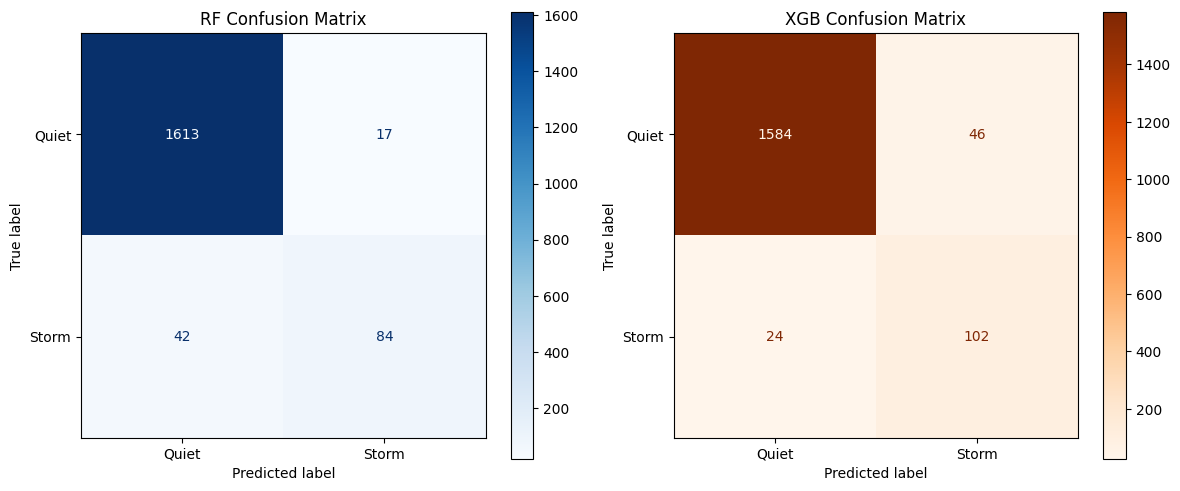

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, rf_scaled_preds,
                                        display_labels=['Quiet', 'Storm'],
                                        cmap='Blues', ax=ax[0])
ax[0].set_title("RF Confusion Matrix")
ConfusionMatrixDisplay.from_predictions(y_test, xgb_scaled_preds,
                                        display_labels=['Quiet', 'Storm'],
                                        cmap='Oranges', ax=ax[1])
ax[1].set_title("XGB Confusion Matrix")
plt.tight_layout()
plt.show()

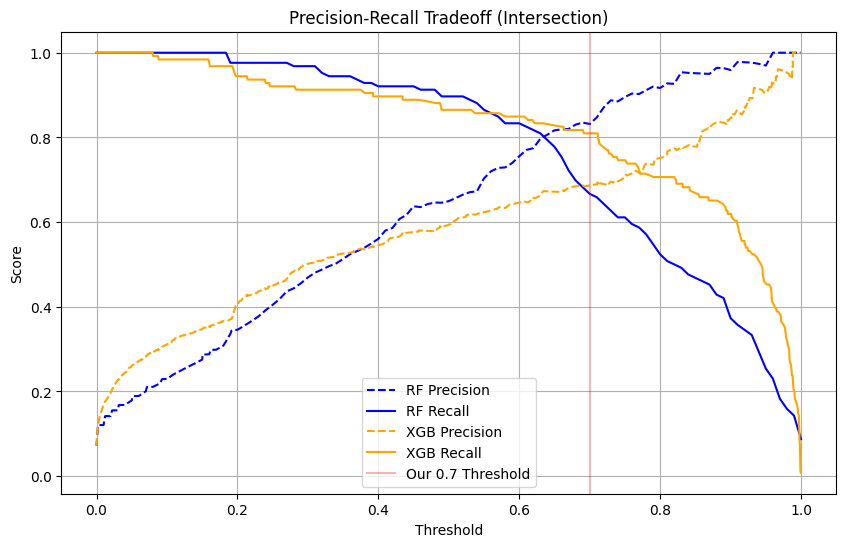

In [ ]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(10, 6))

prec_rf, rec_rf, thresh_rf = precision_recall_curve(y_test, rf_scaled_probs)
plt.plot(thresh_rf, prec_rf[:-1], label="RF Precision", color='blue', linestyle='--')
plt.plot(thresh_rf, rec_rf[:-1], label="RF Recall", color='blue')

prec_xgb, rec_xgb, thresh_xgb = precision_recall_curve(y_test, xgb_scaled_probs)
plt.plot(thresh_xgb, prec_xgb[:-1], label="XGB Precision", color='orange', linestyle='--')
plt.plot(thresh_xgb, rec_xgb[:-1], label="XGB Recall", color='orange')

plt.axvline(0.7, color='red', alpha=0.3, label='Our 0.7 Threshold')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Tradeoff (Intersection)")
plt.legend()
plt.grid(True)
plt.show()

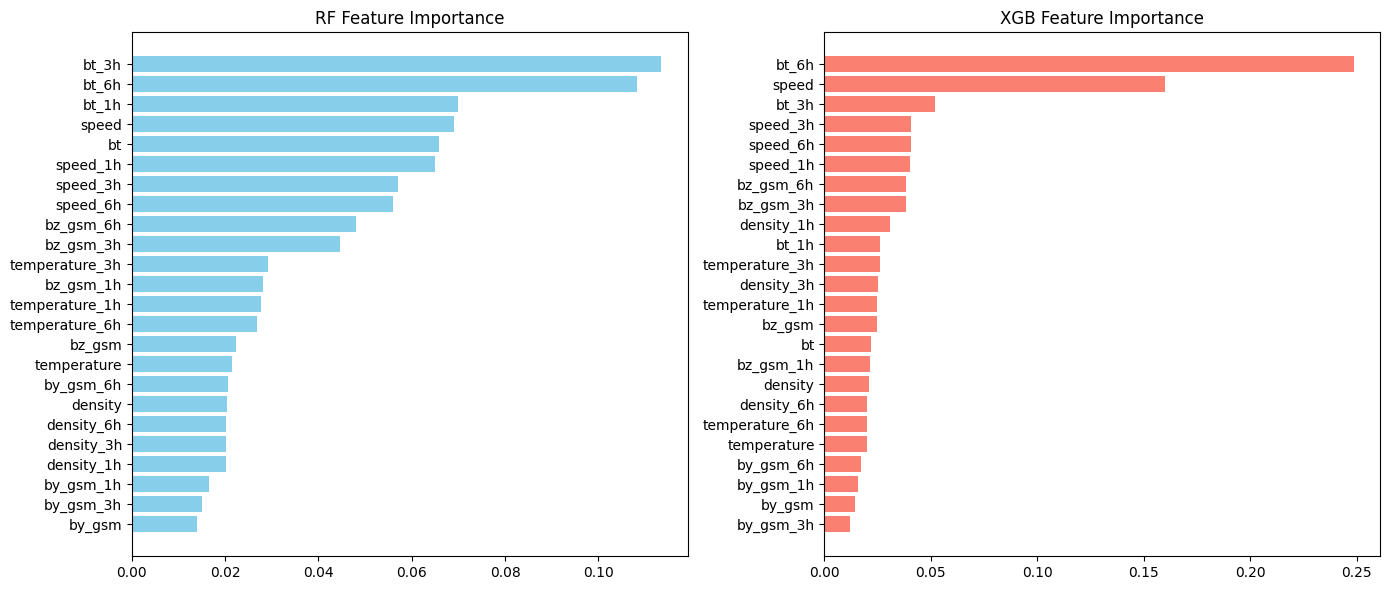

In [ ]:
import numpy as np
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
feature_names = X_train.columns
importances_rf = rf_scaled.feature_importances_
indices_rf = np.argsort(importances_rf)
ax[0].barh(range(len(indices_rf)), importances_rf[indices_rf], color='skyblue')
ax[0].set_yticks(range(len(indices_rf)), [feature_names[i] for i in indices_rf])
ax[0].set_title("RF Feature Importance")

importances_xgb = xgb_scaled.feature_importances_
indices_xgb = np.argsort(importances_xgb)
ax[1].barh(range(len(indices_xgb)), importances_xgb[indices_xgb], color='salmon')
ax[1].set_yticks(range(len(indices_xgb)), [feature_names[i] for i in indices_xgb])
ax[1].set_title("XGB Feature Importance")

plt.tight_layout()
plt.show()

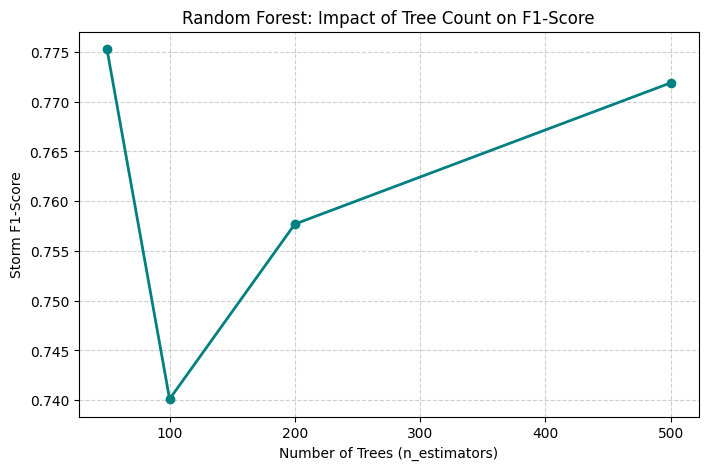

In [ ]:
# =============Plot relationship between parameter values and model performance

import matplotlib.pyplot as plt

# Using the data from your previous experiment loop
plt.figure(figsize=(8, 5))

# Plotting the line
plt.plot(df_results['n_estimators'], df_results['Storm_F1_Score'],
         marker='o', linestyle='-', color='teal', linewidth=2)

# Adding labels
plt.title('Random Forest: Impact of Tree Count on F1-Score', fontsize=12)
plt.xlabel('Number of Trees (n_estimators)', fontsize=10)
plt.ylabel('Storm F1-Score', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()